# 08 - A2a: fallback saat acquisition unavailable

A2a menguji satu perubahan terhadap A1: **pulihkan skor kontrol lama secara persis ketika status tim pemenang skor lama adalah unavailable**. Status supported dan observed_not_supporting_proxy tetap mengikuti A1. Threshold, raw acquisition support, hint, F1 fusion, decoder dan boundary tidak berubah; D1 tidak aktif.

Fallback bukan support acquisition atau hold pemegang possession sebelumnya. Ia memakai evidence yang estimator lama sudah hasilkan dengan pembobotan kualitas yang sama. Saat bola hilang, geometry lama netral tetapi tag masih dapat memberi prior lemah. Saat tag tertinggal atau observasi berkualitas rendah, fallback juga dapat mempertahankan evidence yang salah.

Seluruh scorer dan skenario sintetis berada di src. Notebook membaca CSV/JSON, memverifikasi keluaran, membuat agregasi dan visualisasi. Tidak memakai public GT atau label manual pertandingan.

## 1. Config dan parent

Parent A1 adalah replay diagnostik yang sudah terbukti identik dengan A1 asli. F1 menjadi pembanding legacy control tanpa acquisition. Config A2a hanya menambahkan `control.acquisition.fallback_unavailable: true`; pengaturan penyimpanan terpisah.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'games.py').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.artifacts import list_runs,read_json,read_table
from src.pipeline import run_pipeline
pd.set_option('display.max_columns',None)
A1_RUN_ID='20261116_010846_102998_57f79ee9'
F1_RUN_ID='20261115_232213_442294_bf05582d'
runs=list_runs(project_dir=ROOT)
a1_dir=next(Path(r['path']) for r in runs if r['run_id']==A1_RUN_ID)
f1_dir=next(Path(r['path']) for r in runs if r['run_id']==F1_RUN_ID)
a1_manifest=read_json(a1_dir);f1_manifest=read_json(f1_dir)
a1_pass=a1_manifest['final_core_pass'];f1_pass=f1_manifest['final_core_pass']
MODEL_CONFIG=ROOT/'config/a2a.yaml';STORAGE_CONFIG=ROOT/'config/artifacts_a2a.yaml'
config=yaml.safe_load(MODEL_CONFIG.read_text(encoding='utf-8-sig'))
check=deepcopy(config);assert check['control']['acquisition'].pop('fallback_unavailable') is True
assert check==read_json(a1_dir,'config/model.json')
assert not config.get('live_dead',{}).get('context_stoppage',{}).get('enabled',False)
print('A1 parent:',A1_RUN_ID,'F1 reference:',F1_RUN_ID)
display(config['control']['acquisition'])
display(yaml.safe_load(STORAGE_CONFIG.read_text(encoding='utf-8-sig')))

{'enabled': True, 'window_frames': 5, 'minimum_support_fraction': 0.6, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65, 'fallback_unavailable': True}

{'root_dir': 'artifacts', 'submission_filename': 'baseline_a2a.csv'}

A1 parent: 20261116_010846_102998_57f79ee9 F1 reference: 20261115_232213_442294_bf05582d


## 2. Run terpisah atau buka hasil tersimpan

RUN_A2A=True membuat run baru melalui run_pipeline. Setelah contoh run selesai, default menjadi False dengan run ID yang dipatok. Snapshot konfigurasi dan provenance tersimpan di folder artifacts/run_id/. Validator hanya memeriksa format.

In [2]:
RUN_A2A = False
A2A_RUN_ID = "20261116_024834_385542_009f278f"
if RUN_A2A:
    result=run_pipeline(config,project_dir=ROOT,storage_config_path=STORAGE_CONFIG,
        execution_metadata={'experiment':'A2a_unavailable_fallback','parent_run_id':A1_RUN_ID,
            'reference_f1_run_id':F1_RUN_ID,'notebook':'notebooks/08_control_fallback_experiment.ipynb',
            'model_config_source':str(MODEL_CONFIG)})
    run_dir=Path(result.artifact_dir)
else:
    candidates=[r for r in list_runs(project_dir=ROOT)
        if read_json(r['path']).get('execution',{}).get('experiment')=='A2a_unavailable_fallback']
    if not candidates:raise RuntimeError('Belum ada run A2a; gunakan RUN_A2A=True')
    run_dir=next(Path(r['path']) for r in candidates if r['run_id']==A2A_RUN_ID) if A2A_RUN_ID else Path(candidates[-1]['path'])
manifest=read_json(run_dir);core_pass=manifest['final_core_pass']
assert manifest['status']=='completed' and read_json(run_dir,'config/model.json')==config
print('A2a run:',manifest['run_id'],'folder:',run_dir)
display(read_json(run_dir,'submission/validator/result.json'))

{'status': 'passed', 'message': 'OK    baseline_a2a.csv\n      199319 rows, frame 0..199318\n\n      label counts\n        H    96875   48.6%\n        A    58987   29.6%\n        D     2995    1.5%\n        X    40462   20.3%\n\n      reports 280 possessions of mean 22.3 s\n      (counted with each X as a gap; the scorer bridges abstentions inside a real\n       possession, so its count can be lower than this one)\n\nValid. Note this checks the format only -- it says nothing about whether the labels are right.\nScore it against the public ground truth with run_evaluation.py.'}

A2a run: 20261116_024834_385542_009f278f folder: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261116_024834_385542_009f278f


## 3. Isolasi dan akses data

Perubahan yang diizinkan hanya skor kontrol saat fallback. Fitur, quality, event, transition hint, raw Live/Dead dan utility D harus identik dengan A1. Raw support dan status A1 tetap.

Kolom baru di `core/<pass>/control/components.csv`:

| Kolom | Arti |
|---|---|
| a1_h_score / a1_a_score | Skor sebelum fallback; counterfactual A1 yang dihitung pipeline |
| winner_gate | Gate raw acquisition A1 [0,1]; tetap nol saat unavailable |
| fallback_applied | Boolean: fallback aktif untuk status unavailable |
| effective_gate | Koefisien gap yang diterapkan; 1 saat fallback, bukan confidence atau support baru |
| fallback_restored_gap | Tambahan besar gap dari fallback dibanding A1, satuan utility |
| adjusted_h_score / adjusted_a_score | Skor kontrol akhir setelah fallback |

Metadata definisi tersimpan di control/metadata.json. `diagnostics/final/acquisition/` memisahkan zero gate raw dari effective zero gate; episode lama tetap episode raw support, bukan episode tanpa seluruh evidence.

In [3]:
def join_frame(left,right):
    assert left.frame.is_unique and right.frame.is_unique
    assert np.array_equal(np.sort(left.frame),np.sort(right.frame))
    assert not (set(left.columns)&(set(right.columns)-{'frame'}))
    return left.merge(right,on='frame',validate='one_to_one',sort=True)

paths=[('features/initial/frames.csv','features/initial/frames.csv'),('features/initial/events.csv','features/initial/events.csv')]
for stage,name in [('quality','frames.csv'),('events','frames.csv'),('live_dead','frames.csv'),('fusion','transition_hint.csv'),('fusion','stop_hint.csv'),('fusion','restart_hint.csv')]:
    paths.append((f'core/{a1_pass}/{stage}/{name}',f'core/{core_pass}/{stage}/{name}'))
checks=[]
for old,new in paths:
    same=a1_manifest['files'][old]['sha256']==manifest['files'][new]['sha256'];assert same,new
    checks.append({'artifact':new,'same_sha256':same})
display(pd.DataFrame(checks))
c=read_table(run_dir,f'core/{core_pass}/control/components.csv')
a1_control=read_table(a1_dir,f'core/{a1_pass}/control/scores.csv')
f1_control=read_table(f1_dir,f'core/{f1_pass}/control/scores.csv')
np.testing.assert_array_equal(c.frame,a1_control.frame)
np.testing.assert_array_equal(c.frame,f1_control.frame)
np.testing.assert_array_equal(c[['a1_h_score','a1_a_score']],a1_control[['H','A']])
np.testing.assert_array_equal(c[['legacy_h_score','legacy_a_score']],f1_control[['H','A']])
a1_components=read_table(a1_dir,f'core/{a1_pass}/control/components.csv')
np.testing.assert_array_equal(c.frame,a1_components.frame)
raw_columns=[k for k in a1_components if k.startswith(('pair_valid_','relative_speed_','acquisition_','primary_reason_','evidence_status_','winner_fail_'))]+['winner_gate','winner_primary_reason','winner_evidence_status','legacy_winner','winner_tie']
pd.testing.assert_frame_equal(c[raw_columns],a1_components[raw_columns],check_exact=True)
features=read_table(run_dir,'features/initial/frames.csv')
t=features[['frame','half','graded','ball_ok','ball_speed2d_mps']].copy()
t=join_frame(t,c[['frame','winner_gate','winner_primary_reason','winner_evidence_status','fallback_applied','effective_gate','fallback_restored_gap']])
for model,folder,pass_name in [('f1',f1_dir,f1_pass),('a1',a1_dir,a1_pass),('a2a',run_dir,core_pass)]:
    scores=read_table(folder,f'core/{pass_name}/fusion/state_log_scores.csv').rename(columns={k:f'{model}_{k}' for k in ['H','A','D']})
    t=join_frame(t,scores)
    t=join_frame(t,read_table(folder,'result/labels.csv').rename(columns={'label':f'{model}_final'}))
    t=join_frame(t,read_table(folder,f'core/{pass_name}/decode/labels.csv').rename(columns={'label':f'{model}_decoded'}))
t=join_frame(t,read_table(run_dir,f'core/{core_pass}/fusion/control_components.csv')[['frame','forced_d']])
np.testing.assert_array_equal(t.frame,c.frame)
natural=t.graded&~t.forced_d
np.testing.assert_array_equal(t.a2a_D,t.a1_D)
np.testing.assert_array_equal(t[['a2a_H','a2a_A']].max(axis=1),t[['a1_H','a1_A']].max(axis=1))
print('PASS: upstream, A1 counterfactual, legacy F1 scores, raw support/status, hints and D utility unchanged.')

,artifact,same_sha256
0,features/initial/frames.csv,True
1,features/initial/events.csv,True
2,core/initial/quality/frames.csv,True
3,core/initial/events/frames.csv,True
4,core/initial/live_dead/frames.csv,True
5,core/initial/fusion/transition_hint.csv,True
6,core/initial/fusion/stop_hint.csv,True
7,core/initial/fusion/restart_hint.csv,True


PASS: upstream, A1 counterfactual, legacy F1 scores, raw support/status, hints and D utility unchanged.


## 4. Fallback hanya pada unavailable

Saat fallback, skor harus persis sama dengan legacy F1. Di luar fallback, skor harus persis sama dengan A1. Low quality atau invalid position tetap dapat memicu fallback: itu memulihkan skor yang sudah ada, bukan memperbaiki observasi atau membuktikan skor lama benar. Jika legacy tie, fallback tidak menciptakan preferensi home.

In [4]:
fallback=c.fallback_applied.to_numpy(bool)
np.testing.assert_array_equal(fallback,c.winner_evidence_status.eq('unavailable'))
np.testing.assert_array_equal(c.loc[fallback,['adjusted_h_score','adjusted_a_score']],f1_control.loc[fallback,['H','A']])
np.testing.assert_array_equal(c.loc[~fallback,['adjusted_h_score','adjusted_a_score']],a1_control.loc[~fallback,['H','A']])
assert c.loc[fallback,'winner_gate'].eq(0).all() and c.loc[fallback,'effective_gate'].eq(1).all()
assert not c.loc[c.winner_evidence_status.isin(['supported','observed_not_supporting_proxy','outside_half']),'fallback_applied'].any()
np.testing.assert_allclose(c.adjusted_h_score-c.adjusted_a_score,(c.legacy_h_score-c.legacy_a_score)*c.effective_gate,rtol=0,atol=1e-12)
np.testing.assert_array_equal(t.loc[fallback,['a2a_H','a2a_A']],t.loc[fallback,['f1_H','f1_A']])
np.testing.assert_array_equal(t.loc[~fallback,['a2a_H','a2a_A']],t.loc[~fallback,['a1_H','a1_A']])
print('PASS: exact unavailable-only fallback, no new acquisition support and exact A1 elsewhere.')
display(read_json(run_dir,f'core/{core_pass}/control/metadata.json'))

{'acquisition': {'enabled': True, 'fallback_unavailable': True, 'window_frames': 5, 'minimum_support_fraction': 0.6, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65}, 'fps': 25.0, 'pitch_m': [105.3, 68.0], 'semantics': 'uncalibrated co-motion support, not possession labels or player identities', 'window': 'trailing fixed denominator; full window inside contiguous half/frame block; current cue required', 'relative_speed': 'norm of change in metric ball-minus-nearest-player vector times FPS; both endpoints reliable and near', 'reason_precedence': ['outside_half', 'missing_ball', 'unreliable_ball_motion', 'low_player_quality', 'invalid_position', 'not_near', 'block_start', 'previous_observation_unavailable', 'previous_not_near', 'relative_speed_high', 'insufficient_history', 'insufficient_support', 'supported'], 'reason_semantics': 'failure flags overlap; primary reason is the first failure in precedence, not a causal ranking; unavailable != ob

PASS: exact unavailable-only fallback, no new acquisition support and exact A1 elsewhere.


## 5. Perbandingan perilaku F1, A1 dan A2a

Metrik diambil dari diagnostics produksi. Jumlah short spell yang naik atau turun bukan ukuran accuracy. Perubahan label di luar fallback tetap mungkin karena Viterbi memakai seluruh jalur. Utility D alami harus tetap sama; label D akhir dapat berubah karena jalur temporal/refinement.

In [5]:
rows=[]
for model,folder,pass_name in [('F1',f1_dir,f1_pass),('A1',a1_dir,a1_pass),('A2a',run_dir,core_pass)]:
    diag=read_json(folder,'submission/diagnostics.json')
    core=read_json(folder,f'diagnostics/{pass_name}/core/dead_score_summary.json')
    segments=read_table(folder,'diagnostics/final/prediction/segment_summary.csv')
    transitions=read_table(folder,'diagnostics/final/prediction/transition_counts.csv')
    ha=segments.loc[segments.label.isin(['H','A'])]
    rows.append({'model':model,'HA_spells':diag['possession_spells'],'HA_short_lt_2s':int(ha.segments_lt_2s.sum()),
        'median_HA_duration_s':diag['possession_median_s'],
        'HA_transitions':int(transitions.loc[transitions['from'].isin(['H','A'])&transitions['to'].isin(['H','A']),'count'].sum()),
        'total_transitions':diag['total_transitions'],'natural_D_utility_wins':core['dead_wins_unforced'],
        'natural_D_frames':int(t.loc[natural,f'{model.lower()}_final'].eq('D').sum())})
comparison=pd.DataFrame(rows).set_index('model');display(comparison)
assert comparison.natural_D_utility_wins.nunique()==1
display(pd.crosstab(t.loc[natural,'a1_final'],t.loc[natural,'a2a_final']))
display(pd.crosstab(t.loc[natural,'a2a_decoded'],t.loc[natural,'a2a_final']))

,HA_spells,HA_short_lt_2s,median_HA_duration_s,HA_transitions,total_transitions,natural_D_utility_wins,natural_D_frames
model,,,,,,,
F1,1070,523,2.04,1067,1070,169,63
A1,235,23,12.76,231,236,169,61
A2a,280,25,10.78,276,281,169,61


a2a_final,A,D,H
a1_final,,,
A,51699,0,13946
D,0,61,0
H,7288,0,82929


a2a_final,A,D,H
a2a_decoded,,,
A,58987,0,2
D,0,59,0
H,0,2,96873


## 6. Cakupan fallback dan gap yang dipulihkan

`zero_gate_frames` masih mengukur raw acquisition. Gunakan `effective_zero_gate_frames` untuk melihat gap yang benar-benar dinetralkan setelah fallback. Fallback pada gap yang semula nol tidak menciptakan evidence pembeda. Ringkasan berasal dari pipeline; agregasi per alasan memisahkan jumlah frame dari jumlah utility yang dipulihkan.

Field `zero_gate_removed_nonzero_gap_frames` diwarisi dari audit A1 dan mengacu pada raw gate (berapa gap nonzero yang akan dinetralkan oleh A1), bukan jumlah gap yang tetap hilang sesudah fallback. Untuk A2a gunakan `effective_zero_removed_nonzero_gap_frames`.


In [6]:
audit=read_table(run_dir,'diagnostics/final/acquisition/frames.csv')
summary=read_json(run_dir,'diagnostics/final/acquisition/summary.json')
display(summary)
audit_view=join_frame(audit,t[['frame','a1_final','a2a_final','f1_final']])
audit_view['changed_from_a1']=audit_view.a1_final.ne(audit_view.a2a_final)
g=audit_view.loc[audit_view.natural].copy()
display(g.groupby(['winner_evidence_status','winner_primary_reason','fallback_applied','legacy_gap_nonzero']).agg(
    frames=('frame','size'),restored_gap_sum=('fallback_restored_gap','sum'),changed_frames=('changed_from_a1','sum')))
display(g.groupby(['half','fallback_applied']).agg(frames=('frame','size'),changed_frames=('changed_from_a1','sum'),
    restored_gap_sum=('fallback_restored_gap','sum')))
print('Perubahan label di luar fallback merupakan efek jalur bersama; scorer di sana telah diverifikasi identik A1.')

{'natural_frames': 155923, 'zero_gate_frames': 124918, 'zero_gate_already_zero_gap_frames': 31387, 'zero_gate_removed_nonzero_gap_frames': 93531, 'nonzero_legacy_gap_natural_frames': 124536, 'zero_gate_fraction_given_nonzero_gap': 0.7510358450568511, 'removed_gap_sum': 57245.71344187901, 'legacy_abs_gap_sum': 108174.2803172204, 'fallback_frames': 64811, 'fallback_restored_nonzero_gap_frames': 33424, 'fallback_restored_gap_sum': 6930.06766620354, 'effective_zero_gate_frames': 60107, 'effective_zero_removed_nonzero_gap_frames': 60107, 'gap_nonzero_tolerance': 1e-12, 'semantics': 'descriptive proxy failures, not negative possession labels; primary reasons are exclusive by precedence; flags overlap', 'support_distance': 'within same half, natural support only, 0 at supported frame, NaN if no earlier/later support; future distances diagnostic only', 'tie_selection': 'legacy tie selects the larger gate, H on equal gates; winner_tie is explicit, not a home-control claim', 'fallback_scope': 'w

frames  \
winner_evidence_status        winner_primary_reason            fallback_applied legacy_gap_nonzero           
observed_not_supporting_proxy insufficient_support             False            True                  1940   
                              not_near                         False            True                 36651   
                              previous_not_near                False            True                  1308   
                              relative_speed_high              False            True                 20208   
supported                     supported                        False            True                 31005   
unavailable                   low_player_quality               True             False                   40   
                                                                                True                   387   
                              missing_ball                     True             False                31346   
                                                                                True                 32733   
                              previous_observation_unavailable True             True                   110   
                              unreliable_ball_motion           True             False                    1   
                                                                                True                   194   

                                                                                                    restored_gap_sum  \
winner_evidence_status        winner_primary_reason            fallback_applied legacy_gap_nonzero                     
observed_not_supporting_proxy insufficient_support             False            True                    0.000000e+00   
                              not_near                         False            True                    0.000000e+00   
                              previous_not_near                False            True                    0.000000e+00   
                              relative_speed_high              False            True                    0.000000e+00   
supported                     supported                        False            True                    0.000000e+00   
unavailable                   low_player_quality               True             False                   1.022446e-13   
                                                                                True                    2.037253e+02   
                              missing_ball                     True             False                   0.000000e+00   
                                                                                True                    6.368250e+03   
                              previous_observation_unavailable True             True                    1.520952e+02   
                              unreliable_ball_motion           True             False                   1.221245e-15   
                                                                                True                    2.059972e+02   

                                                                                                    changed_frames  
winner_evidence_status        winner_primary_reason            fallback_applied legacy_gap_nonzero                  
observed_not_supporting_proxy insufficient_support             False            True                            21  
                              not_near                         False            True                          1864  
                              previous_not_near                False            True                            44  
                              relative_speed_high              False            True                           594  
supported                     supported                        False            True                            15  
unavailable                   low_player_quality           

frames  changed_frames  restored_gap_sum
half fallback_applied                                          
1    False              46746            1422          0.000000
     True               32721           11058       3434.557079
2    False              44366            1116          0.000000
     True               32090            7638       3495.510588

Perubahan label di luar fallback merupakan efek jalur bersama; scorer di sana telah diverifikasi identik A1.


## 7. Episode raw support nol dan propagasi jalur

Episode di sini tetap berdasarkan raw gate A1, bukan episode tanpa evidence setelah A2a. Dipilih episode dengan jumlah perubahan label terbanyak secara otomatis. Plot menampilkan gap dan label untuk membedakan pemulihan evidence dari pengaruh jalur temporal; tidak memberi label correctness pada pertandingan.

,episode_id,half,start_frame,end_frame,n_frames,duration_s,primary_reason_mode,unavailable_fraction,not_supporting_proxy_fraction,legacy_gap_nonzero_fraction,ball_observed_fraction,decoded_final_disagreement_frames,changed_frames,fallback_frames,restored_gap_sum
463,463,1,86594,88591,1998,79.92,missing_ball,0.870370,0.129630,0.858859,0.130631,0,1758,1739,221.855797
465,465,1,88693,90651,1959,78.36,missing_ball,0.976519,0.023481,0.145993,0.166922,0,1647,1913,63.197676
278,278,1,46646,48603,1958,78.32,missing_ball,0.959142,0.040858,0.319203,0.042390,0,1382,1878,132.057252
898,898,2,175715,177064,1350,54.00,missing_ball,0.947407,0.052593,0.699259,0.053333,0,1341,1279,177.046829
426,426,1,79873,81228,1356,54.24,missing_ball,0.928466,0.071534,0.905605,0.073746,0,1146,1259,188.838476
664,664,2,135569,136727,1159,46.36,missing_ball,0.911993,0.088007,0.964625,0.089733,0,960,1057,207.321981
419,419,1,78178,79157,980,39.20,missing_ball,0.498980,0.501020,0.502041,0.502041,0,909,489,0.649745
900,900,2,177079,177940,862,34.48,missing_ball,0.726218,0.273782,1.000000,0.274942,0,817,626,123.582597
284,284,1,50231,51064,834,33.36,missing_ball,0.868106,0.131894,0.821343,0.134293,0,766,724,116.419195
448,448,1,84046,84849,804,32.16,missing_ball,0.909204,0.090796,0.799751,0.093284,0,760,731,100.619086


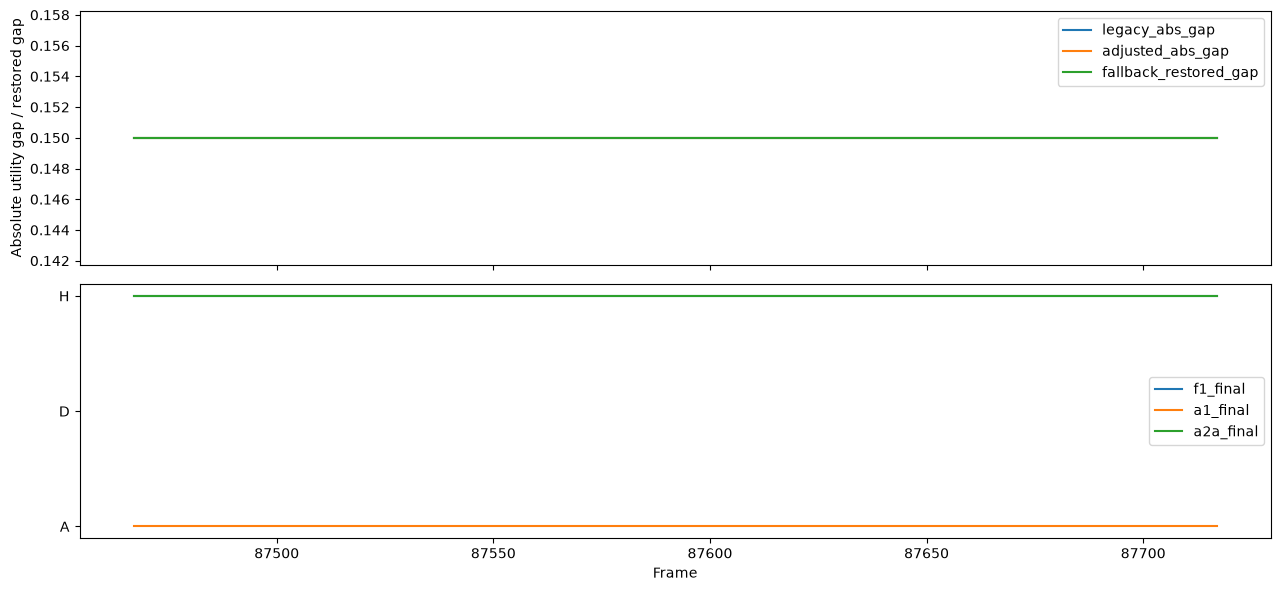

In [7]:
episodes=read_table(run_dir,'diagnostics/final/acquisition/zero_episodes.csv')
changes=g.loc[g.zero_episode_id.ge(0)].groupby('zero_episode_id').agg(changed_frames=('changed_from_a1','sum'),
    fallback_frames=('fallback_applied','sum'),restored_gap_sum=('fallback_restored_gap','sum'))
episode_view=episodes.drop(columns=['removed_gap_sum']).merge(changes,left_on='episode_id',right_index=True,validate='one_to_one')
display(episode_view.sort_values('changed_frames',ascending=False).head(15))
chosen=episode_view.sort_values('changed_frames',ascending=False).iloc[0]
center=(int(chosen.start_frame)+int(chosen.end_frame))//2
w=audit_view.loc[audit_view.frame.between(center-125,center+125)&audit_view.half.eq(chosen.half)&audit_view.natural]
fig,axes=plt.subplots(2,1,figsize=(13,6),sharex=True)
w.plot(x='frame',y=['legacy_abs_gap','adjusted_abs_gap','fallback_restored_gap'],ax=axes[0]);axes[0].set_ylabel('Absolute utility gap / restored gap')
for label in ['f1_final','a1_final','a2a_final']:
    axes[1].step(w.frame,w[label].map({'H':1,'A':-1,'D':0,'X':np.nan}),where='post',label=label)
axes[1].set_yticks([-1,0,1],['A','D','H']);axes[1].legend();axes[1].set_xlabel('Frame')
plt.tight_layout();plt.show()

## 8. Skenario sintetis dan stale-tag limitation

Pipeline menyimpan sebelas skenario di diagnostics/acquisition_synthetic/. Empat tambahan menguji same-team occlusion dengan tag, turnover saat occlusion dengan tag yang mengikuti, turnover dengan tag tertinggal, dan player quality rendah. Setiap skenario juga dihitung dengan counterfactual A1 memakai fungsi produksi yang sama.

**Penting:** `passed` berarti kontrak skenario terpenuhi. Pada `known_limitation_stale_tag`, kontraknya justru mendemonstrasikan bahwa fallback dapat mempertahankan evidence tag lama sehingga kehilangan kecocokan label sintetis sebelum bola kembali terlihat. Lihat checked_label_matches dan limitation_detected; semua passed bukan semua label benar. Expected labels berasal dari konstruksi sintetis, bukan pertandingan. Pemeriksaan label mengecualikan +/-6 frame sekitar batas fase/pergantian owner sintetis.

,scenario,passed,expectation_kind,limitation_detected,checked_label_frames,checked_label_matches,a1_checked_label_matches,changed_from_a1_frames,challenge_fallback_fraction,challenge_effective_zero_fraction,challenge_frames,challenge_zero_gate_fraction,challenge_unavailable_fraction,challenge_not_supporting_proxy_fraction,challenge_both_supported_fraction
0,same_team_pass,True,label_and_support,False,142,142,142,0,0.0,1.000000,40,1.000000,0.0,1.000000,0.000
1,reception_turnover,True,label_and_support,False,155,155,155,0,0.0,0.033333,90,0.033333,0.0,0.033333,0.000
2,short_interception,True,label_and_support,False,142,142,142,0,0.0,0.150000,20,0.150000,0.0,0.150000,0.000
3,loose_ball,True,label_and_support,False,115,115,115,0,0.0,1.000000,40,1.000000,0.0,1.000000,0.000
4,contested_ball,True,label_and_support,False,115,115,115,0,0.0,0.025000,40,0.025000,0.0,0.025000,0.925
5,occlusion,True,label_and_support,False,142,142,142,0,1.0,0.000000,40,1.000000,1.0,0.000000,0.000
6,nearest_player_switch,True,label_and_support,False,142,142,142,0,0.0,0.975000,40,0.975000,0.0,0.975000,0.000
7,occlusion_same_team_tag,True,label_and_support,False,142,142,142,0,1.0,0.000000,40,1.000000,1.0,0.000000,0.000
8,occlusion_turnover_tag,True,label_and_support,False,129,129,129,0,1.0,0.000000,40,1.000000,1.0,0.000000,0.000
9,occlusion_turnover_stale_tag,True,known_limitation_stale_tag,True,129,122,122,3,1.0,0.000000,40,1.000000,1.0,0.000000,0.000


{'source': 'deterministic synthetic feature sequences only; no competition observations, labels or GT', 'expected_labels': 'scenario construction; loose/contested challenge phases unlabelled; +/-6 frames around phase boundaries excluded from label checks', 'scorer': 'production quality, team_control, live_dead, F1 fusion and temporal decoder; no new scoring logic in notebook', 'meaning': 'passing/switch/occlusion can lose acquisition support despite continued team possession; both-supported contested phase is not assigned a ground-truth owner', 'scope': 'behavioral specification checks, not match accuracy or turnover recall', 'passed_semantics': 'scenario contract; known_limitation_stale_tag passes when fallback demonstrably retains stale evidence and loses synthetic label matches before reacquisition; inspect checked_label_matches and limitation_detected separately', 'a1_counterfactual': 'same synthetic features/config with fallback_unavailable=False; scored by production functions', 

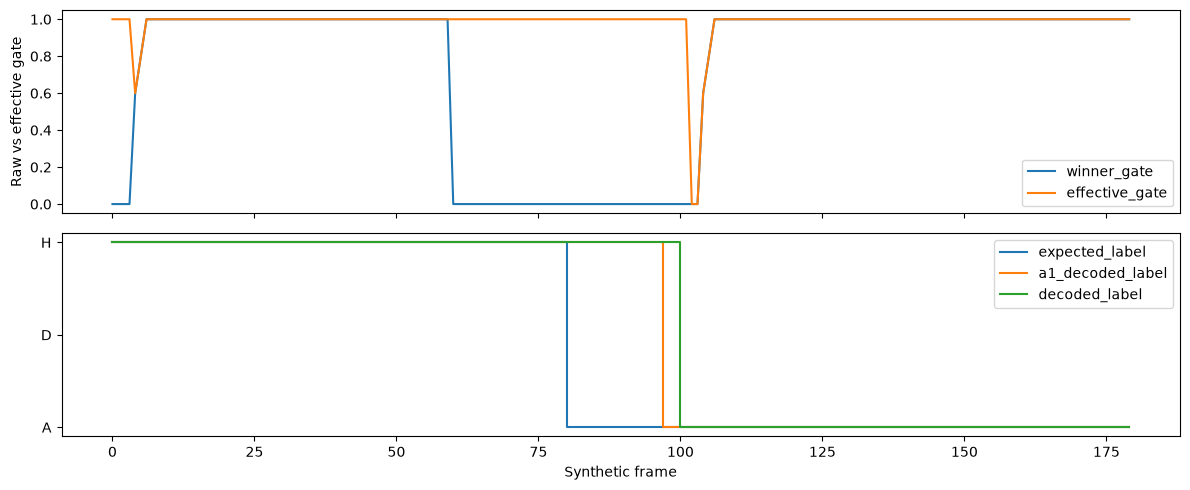

In [8]:
synthetic=read_table(run_dir,'diagnostics/acquisition_synthetic/summary.csv')
synthetic_frames=read_table(run_dir,'diagnostics/acquisition_synthetic/frames.csv')
display(synthetic)
display(read_json(run_dir,'diagnostics/acquisition_synthetic/metadata.json'))
assert len(synthetic)==11 and synthetic.passed.all()
stale=synthetic.loc[synthetic.scenario.eq('occlusion_turnover_stale_tag')].iloc[0]
assert stale.limitation_detected and stale.checked_label_matches<stale.checked_label_frames
s=synthetic_frames.loc[synthetic_frames.scenario.eq('occlusion_turnover_stale_tag')]
fig,axes=plt.subplots(2,1,figsize=(12,5),sharex=True)
s.plot(x='frame',y=['winner_gate','effective_gate'],ax=axes[0]);axes[0].set_ylabel('Raw vs effective gate')
for label in ['expected_label','a1_decoded_label','decoded_label']:
    axes[1].step(s.frame,s[label].map({'H':1,'A':-1,'D':0}),where='post',label=label)
axes[1].set_yticks([-1,0,1],['A','D','H']);axes[1].legend();axes[1].set_xlabel('Synthetic frame')
plt.tight_layout();plt.show()

## 9. Interpretasi dan arah keputusan

| Hasil | Interpretasi / keputusan |
|---|---|
| Exact legacy saat unavailable dan exact A1 di luar fallback | Intervensi terisolasi; lanjutkan diagnosis perilaku |
| Support raw tetap nol tetapi effective gate 1 | Fallback bekerja; bukan acquisition baru |
| Episode tanpa observasi mendapat gap tag kembali | Prior lama dipertahankan; correctness prior belum diketahui |
| Perubahan label menyebar di luar fallback | Pengaruh jalur temporal; tidak berarti scorer berubah di sana |
| Short spell bertambah | Bisa akibat prior tag atau pemulihan pergantian; belum otomatis lebih buruk |
| Stale tag menunda turnover sintetis | Keterbatasan fallback; tidak ada bukti observasi untuk membenarkan incumbent secara universal |
| Not-near/relative-speed tetap meredam gap | A2a belum menyelesaikan acquisition vs continuation; pertimbangkan A2b secara terpisah |

Belum menggabungkan D1, mengganti decoder, atau memilih parameter dari public GT/jumlah spell. Kandidat tetap perlu validasi independen yang diizinkan sebelum klaim accuracy/spellF1.

In [9]:
display(Markdown(f"**Run {manifest['run_id']}:** fallback aktif pada {summary['fallback_frames']:,} frame alami, "
    f"memulihkan gap nonzero pada {summary['fallback_restored_nonzero_gap_frames']:,} frame. "
    f"Effective zero gate tersisa {summary['effective_zero_gate_frames']:,} frame. "
    f"Short H/A {int(comparison.loc['A1','HA_short_lt_2s'])} -> {int(comparison.loc['A2a','HA_short_lt_2s'])}; "
    f"median H/A {comparison.loc['A1','median_HA_duration_s']:.2f} -> {comparison.loc['A2a','median_HA_duration_s']:.2f} detik. "
    "Seluruh scope fallback lolos pemeriksaan; perubahan perilaku ini bukan hasil accuracy/spellF1."))
print('Stale-tag synthetic label matches:',int(stale.checked_label_matches),'/',int(stale.checked_label_frames),
      '; contract:',stale.expectation_kind,'; limitation detected:',bool(stale.limitation_detected))

**Run 20261116_024834_385542_009f278f:** fallback aktif pada 64,811 frame alami, memulihkan gap nonzero pada 33,424 frame. Effective zero gate tersisa 60,107 frame. Short H/A 23 -> 25; median H/A 12.76 -> 10.78 detik. Seluruh scope fallback lolos pemeriksaan; perubahan perilaku ini bukan hasil accuracy/spellF1.

Stale-tag synthetic label matches: 122 / 129 ; contract: known_limitation_stale_tag ; limitation detected: True


## 10. Simpulan run A2a yang tersimpan

Run **20261116_024834_385542_009f278f** dibandingkan dengan A1 **20261116_010846_102998_57f79ee9** dan F1 **20261115_232213_442294_bf05582d**. Pemeriksaan exact-array dan hash lolos: raw support/status, legacy scores, hint, quality, event dan Live/Dead tetap; skor akhir hanya berubah pada unavailable. Di luar fallback, scorer persis A1. Snapshot config dan validator format tersimpan bersama artefak.

| Ukuran | F1 | A1 | A2a |
|---|---:|---:|---:|
| HA spells | 1,070 | 235 | 280 |
| HA spells <2 s | 523 | 23 | 25 |
| Median durasi HA (s) | 2.04 | 12.76 | 10.78 |
| HA transitions | 1,067 | 231 | 276 |
| Natural D utility wins | 169 | 169 | 169 |
| Natural final D frames | 63 | 61 | 61 |

**Efek mekanisme:** fallback aktif pada **64,811 frame alami**. Sebanyak **33,424** memulihkan gap nonzero; fallback pada sisanya tidak menciptakan preferensi baru karena gap lama sudah netral (toleransi 1e-12). Setelah fallback, **60,107 frame alami tetap memiliki effective gate nol**. Support acquisition raw sendiri tidak berubah. A2a tidak menyelesaikan not_near/relative_speed_high.

**Pengaruh pada jalur:** tabel per babak menunjukkan perubahan label juga di luar fallback: 1,422 frame pada babak pertama dan 1,116 pada babak kedua. Skor di lokasi itu telah diverifikasi identik A1, sehingga perbedaan tersebut merupakan efek jalur temporal bersama. Label berbeda tidak memberi tahu model mana yang benar. Penambahan 45 HA spells dan dua short spells juga bukan ukuran penurunan atau kenaikan accuracy.

**Skenario sintetis:** sebelas kontrak perilaku lolos. Fallback memulihkan evidence saat occlusion/quality rendah dan tidak mengubah raw support. Namun pada frame sintetis yang diperiksa, counterfactual A1 sudah memiliki jumlah label cocok yang sama dengan A2a pada semua skenario ini. Jadi suite membuktikan scope dan mengungkap batas, belum membuktikan keuntungan label A2a. Pada plot stale tag, A2a beralih lebih lambat daripada A1 meskipun jumlah label cocok pada mask pemeriksaan sama. Karena pemeriksaan mengecualikan area sekitar batas fase, hitungan cocok tersebut tidak menilai seluruh ketepatan boundary. Ini batas nyata fallback, bukan bukti bahwa A2a lebih baik.

Kasus **stale tag** menghasilkan **122 dari 129** label sintetis yang diperiksa cocok, baik pada A1 maupun A2a. Kontrak known_limitation dinyatakan lolos karena kelemahannya berhasil ditunjukkan, bukan karena semua prediksi benar. Evidence tag yang tertinggal tidak dapat otomatis dianggap benar ketika bola hilang. Acquisition/hint dan observasi sesudah gap dapat memengaruhi boundary; satu skenario belum mengukur recall turnover atau ketepatan boundary pertandingan.

**Keputusan:** A2a berhasil sebagai ablation fallback yang terisolasi dan dapat direproduksi; tetap kandidat eksperimen, belum menggantikan baseline berdasarkan statistik ini. Tidak ada tuning public GT atau penggabungan D1.

**Arah berikutnya:** prioritaskan representasi acquisition vs continuation (A2b). Passing dapat kehilangan co-motion support tanpa kehilangan possession tim. Audit penggunaan komponen tag/proximity/persistence dan transition hint agar tidak menduplikasi evidence, lalu uji kasus yang benar-benar membedakan pengambilalihan kontrol lawan dari kelanjutan dalam tim. Hindari gate tunggal yang menetralkan seluruh evidence hanya karena acquisition tidak teramati. Validasi ketepatan label tetap memerlukan data independen yang diizinkan.
